# 02 – Cleaning, analysis set and features (ClinicalTrials.gov)

**Input:** `data/interim/ctgov_flat.parquet` (notebook 01, Part A – 11,120 trials)

| Part | Content | Block |
|---|---|---|
| A | Dates, exclusion steps, outcome variable, flow diagram, right-censoring check | B5 |
| B | Features part 1: sponsor, healthy volunteers, design, phase, countries/sites | B6 |
| C | Features part 2: indication groups | B7 |

Decisions referenced (see `docs/project_log.md`): D04–D06 (selection, outcome),
D09 (periods), D19 (text-only location matches).

In [1]:
# --- Setup -------------------------------------------------------------------
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

import viz_style as vs

vs.apply()
pd.set_option("display.max_columns", 50)
pd.set_option("display.width", 140)

PROJECT_DIR = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
INTERIM = PROJECT_DIR / "data" / "interim"
PROCESSED = PROJECT_DIR / "data" / "processed"
FIGURES = PROJECT_DIR / "figures"
PROCESSED.mkdir(parents=True, exist_ok=True)

ctgov = pd.read_parquet(INTERIM / "ctgov_flat.parquet")
DATA_NOTE = "Source: ClinicalTrials.gov API v2, data as of 27 Oct 2026"
print(ctgov.shape)

(11120, 44)


## Part A – Analysis set

### A1. Dates

ClinicalTrials.gov dates are either full dates (`2012-05-01`) or month only (`2011-09`).
Month-only dates are set to the first day of the month. Only the **start year** is used
for selection and periods.

In [2]:
def parse_registry_date(s):
    """Parse 'YYYY-MM-DD', 'YYYY-MM' or 'YYYY' to a timestamp (first day for partial dates)."""
    return pd.to_datetime(s, format="mixed", errors="coerce")


DATE_COLUMNS = ["start_date", "primary_completion_date", "completion_date",
                "first_submit_date", "first_post_date", "last_update_post_date"]
for col in DATE_COLUMNS:
    ctgov[f"{col}_dt"] = parse_registry_date(ctgov[col])

ctgov["start_year"] = ctgov["start_date_dt"].dt.year.astype("Int64")

# Check: every non-missing date string was parsed
for col in DATE_COLUMNS:
    n_failed = (ctgov[col].notna() & ctgov[f"{col}_dt"].isna()).sum()
    print(f"{col:<25} missing: {ctgov[col].isna().sum():>5}   unparseable: {n_failed}")

start_date                missing:    33   unparseable: 0
primary_completion_date   missing:   272   unparseable: 0
completion_date           missing:   312   unparseable: 0
first_submit_date         missing:     0   unparseable: 0
first_post_date           missing:     0   unparseable: 0
last_update_post_date     missing:     0   unparseable: 0


### A2. Exclusion steps (flow)

Each step is applied in order; the number of excluded trials and the reason are recorded.

In [3]:
YEAR_MIN, YEAR_MAX = 2005, 2022
FINAL_STATUSES = ["COMPLETED", "TERMINATED"]

flow = [{"step": "Downloaded from ClinicalTrials.gov (interventional, Phase 1 or 1/2, site text match)",
         "remaining": len(ctgov), "excluded": 0, "reason": ""}]


def exclude(df, mask_keep, reason):
    kept = df[mask_keep]
    flow.append({"step": reason, "remaining": len(kept),
                 "excluded": len(df) - len(kept), "reason": reason})
    return kept


df = exclude(ctgov, ctgov["in_target_countries"],
             "No site listed in UK, DE, FR, ES, NL, BE or IT (location search text match only)")
df = exclude(df, df["start_year"].notna(), "Start date missing")
df = exclude(df, df["start_year"] >= YEAR_MIN, f"Start before {YEAR_MIN}")
df = exclude(df, df["start_year"] <= YEAR_MAX, f"Start after {YEAR_MAX}")
window = df.copy()                      # all statuses, start 2005–2022 (used in A4)

status_excluded = window.loc[~window["overall_status"].isin(FINAL_STATUSES), "overall_status"].value_counts()
analysis = exclude(window, window["overall_status"].isin(FINAL_STATUSES),
                   "Status not Completed or Terminated")

flow_df = pd.DataFrame(flow)[["step", "excluded", "remaining"]]
flow_df

,step,excluded,remaining
0,Downloaded from ClinicalTrials.gov (interventi...,0,11120
1,"No site listed in UK, DE, FR, ES, NL, BE or IT...",6,11114
2,Start date missing,33,11081
3,Start before 2005,331,10750
4,Start after 2022,1674,9076
5,Status not Completed or Terminated,1116,7960


In [4]:
print("Excluded by status (start 2005–2022):")
print(status_excluded.to_string())

Excluded by status (start 2005–2022):
overall_status
UNKNOWN                    469
ACTIVE_NOT_RECRUITING      330
RECRUITING                 186
WITHDRAWN                  107
SUSPENDED                   22
ENROLLING_BY_INVITATION      2


### A3. Outcome variable and periods

* `terminated` = 1 if TERMINATED, 0 if COMPLETED (D06)
* `period`: **pre** = 2005–2015, **transition** = 2016 (BIA 10-2474), **post** = 2017–2022.
  2016 stays in the analysis set; it is only left out of the pre/post comparison (D09).

In [5]:
analysis = analysis.copy()
analysis["terminated"] = (analysis["overall_status"] == "TERMINATED").astype(int)
analysis["period"] = pd.cut(analysis["start_year"].astype(int), bins=[2004, 2015, 2016, 2022],
                            labels=["pre (2005-2015)", "transition (2016)", "post (2017-2022)"])

n, n_term = len(analysis), analysis["terminated"].sum()
print(f"Analysis set: {n:,} trials | terminated: {n_term:,} ({100 * n_term / n:.1f} %)\n")
summary = analysis.groupby("period", observed=True)["terminated"].agg(trials="size", terminated="sum")
summary["terminated_pct"] = (100 * summary["terminated"] / summary["trials"]).round(1)
summary

Analysis set: 7,960 trials | terminated: 1,154 (14.5 %)



,trials,terminated,terminated_pct
period,,,
pre (2005-2015),4644,469,10.1
transition (2016),513,65,12.7
post (2017-2022),2803,620,22.1


In [6]:
# Start dates in the analysis set that are still flagged as estimated
print(analysis["start_date_type"].value_counts(dropna=False).to_string())

start_date_type
ACTUAL    4426
NaN       3534


### A4. Right-censoring check: share of trials without final status by start year

Trials that started recently are more often still running. If a large share of a start
year has no final status yet, the completed/terminated trials of that year are a selected
(mostly short) subgroup. This determines the cut-off for sensitivity analyses.

In [7]:
status_group = pd.Series("Open (recruiting / active / suspended)", index=window.index)
status_group[window["overall_status"].isin(FINAL_STATUSES)] = "Final (completed / terminated)"
status_group[window["overall_status"] == "UNKNOWN"] = "Unknown"
status_group[window["overall_status"] == "WITHDRAWN"] = "Withdrawn"

by_year = pd.crosstab(window["start_year"], status_group, normalize="index").mul(100).round(1)
by_year["n_trials"] = window["start_year"].value_counts().sort_index()
by_year

col_0,Final (completed / terminated),Open (recruiting / active / suspended),Unknown,Withdrawn,n_trials
start_year,,,,,
2005,90.5,1.2,7.7,0.6,168
2006,90.9,0.5,8.2,0.5,220
2007,94.8,0.7,4.6,0.0,306
2008,93.6,0.5,4.6,1.3,373
2009,93.1,0.4,4.9,1.6,509
2010,94.3,0.0,4.2,1.5,546
2011,95.1,0.2,3.7,1.1,547
2012,94.2,0.2,5.1,0.6,534
2013,93.6,0.7,4.9,0.7,546


Saved figure: diag_open_status_by_start_year.png


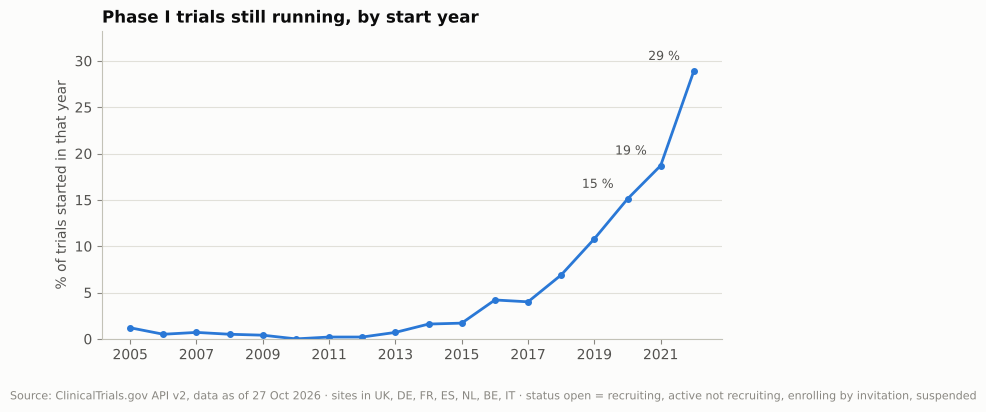

In [8]:
open_share = by_year["Open (recruiting / active / suspended)"]
fig, ax = plt.subplots(figsize=(8, 4))
ax.plot(open_share.index.astype(int), open_share.values, color=vs.SERIES[0], marker="o", markersize=4)
ax.set_ylim(0, max(30, open_share.max() * 1.15))
ax.set_xticks(range(YEAR_MIN, YEAR_MAX + 1, 2))
ax.set_ylabel("% of trials started in that year")
ax.set_title("Phase I trials still running, by start year")
for year in (2020, 2021, 2022):
    ax.annotate(f"{open_share.loc[year]:.0f} %", (year, open_share.loc[year]),
                textcoords="offset points", xytext=(-10, 8), ha="right",
                fontsize=9, color=vs.INK_SECONDARY)
vs.source_note(fig, DATA_NOTE + " · sites in UK, DE, FR, ES, NL, BE, IT · status open = recruiting, "
               "active not recruiting, enrolling by invitation, suspended")
vs.save(fig, FIGURES / "diag_open_status_by_start_year.png")
plt.show()

In [9]:
# 'Unknown' status by period – could hide unreported terminations
unknown_by_period = (window.assign(period=pd.cut(window["start_year"].astype(int), [2004, 2015, 2016, 2022],
                                                 labels=["pre", "2016", "post"]))
                     .groupby("period", observed=True)["overall_status"]
                     .apply(lambda s: round(100 * (s == "UNKNOWN").mean(), 1)))
print("% of trials with status UNKNOWN (start 2005–2022):")
print(unknown_by_period.to_string())

% of trials with status UNKNOWN (start 2005–2022):
period
pre     4.9
2016    5.9
post    5.4


### A5. Flow diagram

Saved figure: 01_flow_diagram.png


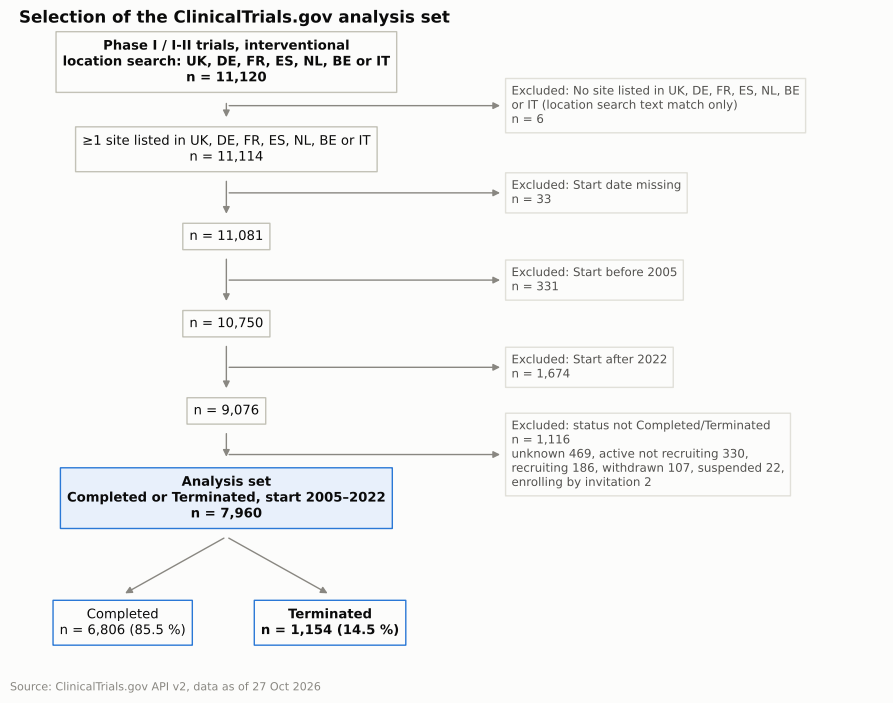

In [10]:
def draw_flow(flow_df, status_excluded, n_completed, n_terminated, path):
    """Vertical flow diagram: main boxes on the left, exclusions on the right, outcome split below."""
    fig, ax = plt.subplots(figsize=(9, 7.0))
    ax.set_axis_off()
    ax.grid(False)
    main_x, side_x, w_main = 0.02, 0.56, 0.44
    box = dict(boxstyle="round,pad=0.5,rounding_size=0.02", linewidth=1)
    rows = len(flow_df)
    ys = np.linspace(0.95, 0.25, rows)

    labels_main = [
        f"Phase I / I-II trials, interventional\nlocation search: UK, DE, FR, ES, NL, BE or IT\nn = {flow_df.loc[0, 'remaining']:,}",
        f"≥1 site listed in UK, DE, FR, ES, NL, BE or IT\nn = {flow_df.loc[1, 'remaining']:,}"]
    for i in range(2, rows - 1):
        labels_main.append(f"n = {flow_df.loc[i, 'remaining']:,}")
    labels_main.append(f"Analysis set\nCompleted or Terminated, start 2005–2022\nn = {flow_df.loc[rows - 1, 'remaining']:,}")

    half_h = [{2: 0.05, 1: 0.035}.get(label.count("\n"), 0.02) for label in labels_main]
    for i, (y, label) in enumerate(zip(ys, labels_main)):
        final = i == rows - 1
        ax.text(main_x + w_main / 2, y, label, ha="center", va="center", fontsize=9.5,
                fontweight="bold" if final or i == 0 else "normal", color=vs.INK_PRIMARY,
                bbox={**box, "facecolor": "#e8f0fb" if final else vs.SURFACE,
                      "edgecolor": vs.SERIES[0] if final else vs.BASELINE})
        if i < rows - 1:
            ax.annotate("", xy=(main_x + w_main / 2, ys[i + 1] + half_h[i + 1] + 0.012),
                        xytext=(main_x + w_main / 2, y - half_h[i] - 0.012),
                        arrowprops=dict(arrowstyle="-|>", color=vs.INK_MUTED, lw=1))
        if i >= 1:
            excl = flow_df.loc[i, "excluded"]
            text = "Excluded: " + "\n".join(_wrap(flow_df.loc[i, "step"], 40)) + f"\nn = {excl:,}"
            if i == rows - 1:
                details = ", ".join(f"{k.replace('_', ' ').lower()} {v:,}" for k, v in status_excluded.items())
                text = f"Excluded: status not Completed/Terminated\nn = {excl:,}\n" + "\n".join(
                    _wrap(details, 44))
            y_side = (ys[i - 1] + ys[i]) / 2
            ax.annotate("", xy=(side_x, y_side), xytext=(main_x + w_main / 2, y_side),
                        arrowprops=dict(arrowstyle="-|>", color=vs.INK_MUTED, lw=1))
            ax.text(side_x + 0.01, y_side, text, ha="left", va="center", fontsize=8.5,
                    color=vs.INK_SECONDARY, bbox={**box, "facecolor": vs.SURFACE, "edgecolor": vs.GRID})
    # Outcome split below the analysis set
    x_center, y_out = main_x + w_main / 2, 0.05
    n_total = n_completed + n_terminated
    for x_off, label, bold in [(-0.12, f"Completed\nn = {n_completed:,} ({100 * n_completed / n_total:.1f} %)", False),
                               (0.12, f"Terminated\nn = {n_terminated:,} ({100 * n_terminated / n_total:.1f} %)", True)]:
        ax.annotate("", xy=(x_center + x_off, y_out + 0.045), xytext=(x_center, ys[-1] - half_h[-1] - 0.012),
                    arrowprops=dict(arrowstyle="-|>", color=vs.INK_MUTED, lw=1))
        ax.text(x_center + x_off, y_out, label, ha="center", va="center", fontsize=9.5,
                fontweight="bold" if bold else "normal", color=vs.INK_PRIMARY,
                bbox={**box, "facecolor": vs.SURFACE, "edgecolor": vs.SERIES[0]})
    ax.set_xlim(0, 1); ax.set_ylim(0, 1)
    ax.set_title("Selection of the ClinicalTrials.gov analysis set")
    fig.subplots_adjust(left=0.02, right=0.98, top=0.95, bottom=0.06)
    vs.source_note(fig, DATA_NOTE, y=0.02)
    vs.save(fig, path)
    return fig


def _wrap(text, width):
    words, lines, line = text.split(" "), [], ""
    for word in words:
        if len(line) + len(word) + 1 > width:
            lines.append(line)
            line = word
        else:
            line = f"{line} {word}".strip()
    return lines + [line]


draw_flow(flow_df, status_excluded, n_completed=int((analysis["terminated"] == 0).sum()),
          n_terminated=int(analysis["terminated"].sum()), path=FIGURES / "01_flow_diagram.png")
plt.show()

### A6. Save

In [11]:
flow_df.to_csv(PROCESSED / "flow_counts_ctgov.csv", index=False)
analysis.to_parquet(INTERIM / "ctgov_analysis_base.parquet", index=False)
window.to_parquet(INTERIM / "ctgov_window_2005_2022_all_statuses.parquet", index=False)
print(f"Analysis set saved: {len(analysis):,} rows")
print(f"Window (all statuses) saved: {len(window):,} rows")

Analysis set saved: 7,960 rows
Window (all statuses) saved: 9,076 rows


### A7. Summary of Part A

| Step | Excluded | Remaining |
|---|---|---|
| Downloaded | – | 11,120 |
| No site listed in a target country (location text match only) | 6 | 11,114 |
| Start date missing | 33 | 11,081 |
| Start before 2005 | 331 | 10,750 |
| Start after 2022 | 1,674 | 9,076 |
| Status not Completed/Terminated (unknown 469, active 330, recruiting 186, withdrawn 107, suspended 22, by invitation 2) | 1,116 | **7,960** |

**Analysis set:** 7,960 trials, 1,154 terminated (**14.5 %**).

Crude termination share by period: pre 10.1 % · 2016 12.7 % · post 22.1 %.

**Caution – right-censoring:** the share of trials still running rises from < 2 % (start
before 2015) to 11 % (2019), 15 % (2020), 19 % (2021) and 29 % (2022). Terminated trials
reach a final status faster than completed ones, so for recent start years the
terminated share among *final* trials is biased upwards. The crude pre/post difference must
therefore not be interpreted before the sensitivity analyses in Block 14 (e.g. start
≤ 2019 / ≤ 2020, adjusted models). The share of trials with status UNKNOWN is similar across
periods (4.9 % / 5.9 % / 5.4 %).

## Part B – Features part 1 (Block 6)

Each feature is assessed for **data leakage** – the model may only use information that is
known when a trial starts:

* ✅ **known at start** – design and population as planned
* ⚠️ **may be updated after start** – e.g. site lists; used, but checked in a sensitivity
  analysis without them
* ❌ **post-start information** – only used descriptively, never as a model feature

### B1. Placebo and intervention names from the raw records

The flat table holds arm *types* only. A trial counts as placebo-controlled if it has an arm
of type `PLACEBO_COMPARATOR` **or** an intervention or arm whose name contains "placebo".

In [12]:
import gzip
import json

RAW_FILE = PROJECT_DIR / "data" / "raw" / "ctgov" / "ctgov_phase1_europe_raw.jsonl.gz"
ids = set(window["nct_id"])   # features for ALL started trials (window), reports on the analysis set
placebo_named = {}
with gzip.open(RAW_FILE, "rt", encoding="utf-8") as f:
    for line in f:
        s = json.loads(line)
        nct = s["protocolSection"]["identificationModule"]["nctId"]
        if nct not in ids:
            continue
        arms = s["protocolSection"].get("armsInterventionsModule", {})
        names = [i.get("name", "") for i in arms.get("interventions", [])] + \
                [a.get("label", "") for a in arms.get("armGroups", [])]
        placebo_named[nct] = any("placebo" in n.lower() for n in names)

# Features are computed for all 9,076 trials started 2005–2022 (needed for the fixed observation
# window in notebook 05); all checks below are reported for the analysis set (mask A).
feat = window.copy()
feat["terminated"] = (feat["overall_status"] == "TERMINATED").astype(int)
feat["period"] = pd.cut(feat["start_year"].astype(int), bins=[2004, 2015, 2016, 2022],
                        labels=["pre (2005-2015)", "transition (2016)", "post (2017-2022)"])
A = feat["overall_status"].isin(FINAL_STATUSES)
feat["placebo"] = (feat["arm_group_types"].fillna("").str.contains("PLACEBO_COMPARATOR")
                   | feat["nct_id"].map(placebo_named)).astype(int)
print(f"Placebo-controlled: {feat.loc[A, 'placebo'].sum():,} ({100 * feat.loc[A, 'placebo'].mean():.1f} %)")
print(f"  ... via arm type only : {feat.loc[A, 'arm_group_types'].fillna('').str.contains('PLACEBO_COMPARATOR').sum():,}")

Placebo-controlled: 2,202 (27.7 %)
  ... via arm type only : 1,564


### B2. Sponsor, population, design

In [13]:
# Sponsor
feat["industry_sponsor"] = (feat["lead_sponsor_class"] == "INDUSTRY").astype(int)
feat["sponsor_group"] = feat["lead_sponsor_class"].map(
    {"INDUSTRY": "Industry", "OTHER": "Academic / other"}).fillna("Government / network / other")
feat["industry_collaborator"] = feat["collaborator_classes"].fillna("").str.contains("INDUSTRY").astype(int)

# Population – healthy volunteers: 6 missing values imputed from the condition text
hv_missing = feat["healthy_volunteers"].isna()
hv_from_text = feat["conditions"].fillna("").str.contains(r"\bhealthy\b", case=False)
feat["healthy_volunteers_imputed"] = hv_missing.astype(int)
feat["healthy_volunteers"] = feat["healthy_volunteers"].astype("boolean").fillna(hv_from_text).astype(int)
feat["includes_children"] = feat["std_ages"].fillna("").str.contains("CHILD").astype(int)
feat["male_only"] = (feat["sex"] == "MALE").astype(int)
print(f"Healthy volunteers: {feat.loc[A, 'healthy_volunteers'].sum():,} ({100 * feat.loc[A, 'healthy_volunteers'].mean():.1f} %), "
      f"imputed: {hv_missing[A].sum()}")

# Phase and design
feat["phase_1_2"] = (feat["phases"] == "PHASE1|PHASE2").astype(int)
feat["randomized"] = (feat["allocation"] == "RANDOMIZED").astype(int)
MASKING_LEVEL = {"NONE": 0, "SINGLE": 1, "DOUBLE": 2, "TRIPLE": 3, "QUADRUPLE": 4}
feat["masking_level"] = feat["masking"].map(MASKING_LEVEL).fillna(0).astype(int)
feat["blinded"] = (feat["masking_level"] > 0).astype(int)
feat["intervention_model"] = feat["intervention_model"].fillna("NOT_REPORTED")
MAIN_PURPOSES = ["TREATMENT", "BASIC_SCIENCE", "PREVENTION", "OTHER"]
feat["primary_purpose_group"] = feat["primary_purpose"].where(
    feat["primary_purpose"].isin(MAIN_PURPOSES), "OTHER").where(feat["primary_purpose"].notna(), "NOT_REPORTED")
feat["has_dmc_cat"] = feat["has_dmc"].map({True: "yes", False: "no"}).fillna("not reported")

# Intervention type
itypes = feat["intervention_types"].fillna("")
feat["biological"] = itypes.str.contains("BIOLOGICAL|GENETIC").astype(int)
feat["drug"] = itypes.str.contains("DRUG").astype(int)

Healthy volunteers: 3,718 (46.7 %), imputed: 6


### B3. Countries and sites (⚠️)

Site lists reflect the latest registry update. The site status (e.g. "withdrawn" sites that
were never activated) is not available for ended trials, so a later removal of sites cannot
be detected. Terminated trials have *more* sites (median 5 vs. 1), which reflects multi-centre
patient trials rather than removed sites. Counts are log-transformed for the model.

In [14]:
EUROPE_EXTRA = {"Switzerland", "Austria", "Denmark", "Sweden", "Norway", "Finland", "Poland", "Czechia",
                "Hungary", "Ireland", "Portugal", "Greece", "Romania", "Bulgaria", "Slovakia", "Slovenia",
                "Croatia", "Estonia", "Latvia", "Lithuania", "Luxembourg", "Iceland", "Malta", "Cyprus",
                "Serbia", "Ukraine", "Russian Federation", "Turkey", "Türkiye", "Belarus", "Georgia",
                "Moldova", "Bosnia and Herzegovina", "North Macedonia", "Albania", "Montenegro", "Israel"}
EUROPE = set(TARGET_COUNTRIES := ["United Kingdom", "Germany", "France", "Spain",
                                  "Netherlands", "Belgium", "Italy"]) | EUROPE_EXTRA
country_lists = feat["location_countries"].fillna("").str.split("|")
feat["multinational"] = (feat["n_countries"] > 1).astype(int)
feat["site_outside_europe"] = country_lists.apply(lambda cs: any(c and c not in EUROPE for c in cs)).astype(int)
feat["site_in_us"] = country_lists.apply(lambda cs: "United States" in cs).astype(int)
feat["log_n_locations"] = np.log1p(feat["n_locations"])
feat["log_n_countries"] = np.log1p(feat["n_countries"])

print(feat[A].groupby("terminated")[["n_locations", "n_countries"]].median().rename(index={0: "completed", 1: "terminated"}))

            n_locations  n_countries
terminated                          
completed           1.0          1.0
terminated          5.0          2.0


### B4. Post-start information (❌ descriptive only)

* **Actual enrollment** – terminated trials report the number actually enrolled (D12).
* **Registration after the primary completion date** – such trials were registered when their
  outcome was already known. 10.6 % of completed but only 2.7 % of terminated trials were
  registered this way → selection effect, excluded from the model (D28) and tested in a
  sensitivity analysis.
* **Results posted** – happens after the trial ends.

In [15]:
feat["registered_after_completion"] = (feat["first_submit_date_dt"] > feat["primary_completion_date_dt"]).astype(int)
feat["registration_lag_days"] = (feat["first_submit_date_dt"] - feat["start_date_dt"]).dt.days
feat["registered_prospectively"] = (feat["registration_lag_days"] <= 30).astype(int)
feat["enrollment_actual"] = feat["enrollment_count"].where(feat["enrollment_type"] == "ACTUAL")
feat["has_results_posted"] = feat["has_results"].astype(int)

print(feat[A].groupby("terminated")[["registered_after_completion", "registered_prospectively", "has_results_posted"]]
      .mean().mul(100).round(1).rename(index={0: "completed", 1: "terminated"}))

            registered_after_completion  registered_prospectively  has_results_posted
terminated                                                                           
completed                          10.6                      71.5                21.2
terminated                          2.7                      83.0                33.3


### B5. Leakage assessment and univariate check

Termination share per feature value – a plausibility check only (the descriptive analysis
follows in notebook 04).

In [16]:
LEAKAGE = pd.DataFrame([
    ("industry_sponsor / sponsor_group", "✅ known at start", "model"),
    ("industry_collaborator", "✅ known at start", "model"),
    ("healthy_volunteers", "✅ known at start", "model"),
    ("includes_children, male_only", "✅ known at start", "model"),
    ("phase_1_2", "✅ known at start", "model"),
    ("randomized, masking_level / blinded, placebo", "✅ known at start", "model"),
    ("intervention_model, primary_purpose_group", "✅ known at start", "model"),
    ("biological, drug", "✅ known at start", "model"),
    ("has_dmc_cat", "✅ known at start (often not reported)", "model"),
    ("start_year", "✅ known at start", "model"),
    ("log_n_locations, log_n_countries, multinational, site_outside_europe, site_in_us",
     "⚠️ may be updated after start", "model + sensitivity without"),
    ("enrollment_actual", "❌ post-start", "descriptive only"),
    ("registered_after_completion, registered_prospectively", "❌ post-start / selection", "descriptive + sensitivity"),
    ("has_results_posted", "❌ post-start", "descriptive only"),
], columns=["feature", "leakage assessment", "use"])
LEAKAGE

,feature,leakage assessment,use
0,industry_sponsor / sponsor_group,✅ known at start,model
1,industry_collaborator,✅ known at start,model
2,healthy_volunteers,✅ known at start,model
3,"includes_children, male_only",✅ known at start,model
4,phase_1_2,✅ known at start,model
5,"randomized, masking_level / blinded, placebo",✅ known at start,model
6,"intervention_model, primary_purpose_group",✅ known at start,model
7,"biological, drug",✅ known at start,model
8,has_dmc_cat,✅ known at start (often not reported),model
9,start_year,✅ known at start,model


In [17]:
CHECK = ["sponsor_group", "industry_collaborator", "healthy_volunteers", "includes_children", "male_only",
         "phase_1_2", "randomized", "masking_level", "placebo", "biological", "intervention_model",
         "primary_purpose_group", "has_dmc_cat", "multinational", "site_outside_europe"]
rows = []
for col in CHECK:
    g = feat[A].groupby(col, observed=True)["terminated"].agg(["size", "mean"])
    for val, r in g.iterrows():
        rows.append({"feature": col, "value": val, "trials": int(r["size"]),
                     "terminated_pct": round(100 * r["mean"], 1)})
univariate = pd.DataFrame(rows)
univariate.to_csv(PROCESSED / "univariate_check_part1.csv", index=False)
univariate

,feature,value,trials,terminated_pct
0,sponsor_group,Academic / other,1630,13.7
1,sponsor_group,Government / network / other,76,7.9
2,sponsor_group,Industry,6254,14.8
3,industry_collaborator,0,6830,14.5
4,industry_collaborator,1,1130,14.5
5,healthy_volunteers,0,4242,21.5
6,healthy_volunteers,1,3718,6.5
7,includes_children,0,7489,14.1
8,includes_children,1,471,20.8
9,male_only,0,6572,15.9


### B6. Save

In [18]:
feat[A].to_parquet(INTERIM / "ctgov_features_part1.parquet", index=False)
print(f"Saved {A.sum():,} rows x {feat.shape[1]} columns (analysis set); features also computed for "
      f"{(~A).sum():,} further started trials (window)")

Saved 7,960 rows x 78 columns (analysis set); features also computed for 1,116 further started trials (window)


### B7. Summary of Part B

* 20+ features derived; leakage assessment documented above (✅ / ⚠️ / ❌).
* Placebo-controlled: 2,202 trials (27.7 %) – 638 of them identified only via intervention
  or arm names.
* Healthy volunteers: 3,718 (46.7 %); 6 missing values imputed from the condition text.
* Univariate termination shares (plausibility check, not adjusted):
  healthy volunteers **6.5 %** vs. patients **21.5 %**; Phase 1/2 24.6 % vs. Phase 1 11.7 %;
  multinational 25.7 % vs. 9.1 %; crossover 4.0 % vs. sequential (dose escalation) 28.1 %;
  industry 14.8 % vs. academic 13.7 %.
* Post-start information (actual enrollment, registration after completion, results posted)
  is excluded from the model. Trials registered after their primary completion date
  (10.6 % of completed vs. 2.7 % of terminated trials) indicate selective retrospective
  registration → sensitivity analysis without them.
* "Not reported" categories (primary purpose, DMC) have low termination shares – they mark
  older records and partly act as a proxy for registration era; keep in mind for the model.

## Part C – Indication groups (Block 7)

Nine groups (`mappings/condition_groups.csv`), assigned in this order:

1. **MeSH categories** – each trial's condition MeSH terms *and their ancestors* are matched
   against the top-level MeSH categories of each group; if several groups match, the group
   with the **highest priority** wins (Oncology > Infectious > Nervous system > Cardiovascular >
   Metabolic > Immunology > Respiratory > Other).
2. **Free-text keywords** – only for trials without a MeSH match (30 % of trials have no MeSH
   terms, mostly healthy-volunteer trials).
3. **Healthy volunteers – no target condition** – no disease matched, and the trial lists
   e.g. "Healthy" or a PK/BE/DDI topic as condition, or accepts healthy volunteers.
4. **Overrides** (`mappings/condition_group_overrides.csv`) – documented corrections for known
   borderline cases (B2, B3, B6, B8, B10) and free-text abbreviations; each override only moves
   a trial *from* a stated group.
5. Anything left → "Other diseases" (flagged as `unclassified_fallback`).

Borderline cases for the domain expert are listed in `validation/condition_groups_borderline_review.csv`.

In [19]:
import re

rules = pd.read_csv(PROJECT_DIR / "mappings" / "condition_groups.csv").sort_values("priority")
overrides = pd.read_csv(PROJECT_DIR / "mappings" / "condition_group_overrides.csv")
HV_GROUP = "Healthy volunteers – no target condition"
OTHER_GROUP = "Other diseases"
disease_rules = rules[rules["group"] != HV_GROUP]
hv_pattern = rules.loc[rules["group"] == HV_GROUP, "free_text_keywords"].iloc[0]


def mesh_terms(row):
    """Condition MeSH terms plus ancestors, commas removed (as in the category names)."""
    text = f"{row['condition_mesh_terms'] or ''}|{row['condition_mesh_ancestors'] or ''}"
    return {t.replace(",", "") for t in text.split("|") if t}


def assign_group(row):
    terms, cond = mesh_terms(row), (row["conditions"] or "").lower()
    mesh_hits = [r.group for r in disease_rules.itertuples()
                 if terms & set(str(r.mesh_category_terms).split("|"))]
    text_hits = [r.group for r in disease_rules.itertuples() if re.search(r.free_text_keywords, cond)]
    if mesh_hits:
        group, source = mesh_hits[0], "mesh"
    elif text_hits:
        group, source = text_hits[0], "free_text"
    elif re.search(hv_pattern, cond) or row["healthy_volunteers"] == 1:
        group, source = HV_GROUP, "healthy_volunteer_rule"
    else:
        group, source = OTHER_GROUP, "unclassified_fallback"

    case = None
    for o in overrides.itertuples():
        if group == o.from_group and re.search(o.pattern, cond):
            group, source, case = o.to_group, "override", o.case_id
            break
    disease_groups = sorted(set(mesh_hits or text_hits) - {OTHER_GROUP})
    return pd.Series({"indication_group": group, "indication_source": source,
                      "override_case": case, "n_disease_groups_matched": len(disease_groups),
                      "disease_groups_matched": "|".join(disease_groups) or None})


groups = feat.apply(assign_group, axis=1)
feat = pd.concat([feat.drop(columns=groups.columns, errors="ignore"), groups], axis=1)
feat_window = feat.copy()          # all started trials 2005–2022 (for notebook 05)
feat = feat[A].copy()              # analysis set – all reports and decisions below refer to it

GROUP_ORDER = list(rules.sort_values("priority")["group"])
print(pd.crosstab(feat["indication_group"], feat["indication_source"], margins=True)
      .reindex(GROUP_ORDER + ["All"]).to_string())
print(f"\nTrials matching more than one disease group (resolved by priority): "
      f"{(feat['n_disease_groups_matched'] > 1).sum():,}")

indication_source                         free_text  healthy_volunteer_rule  mesh  override  unclassified_fallback   All
indication_group                                                                                                        
Oncology                                        385                       0  2258        37                      0  2680
Infectious diseases & vaccines                   72                       0   589         0                      0   661
Nervous system & mental disorders                50                       0   620        63                      0   733
Cardiovascular                                   25                       0   233         0                      0   258
Metabolic & endocrine                            17                       0   497         8                      0   522
Immunology & inflammation                        73                       0   273        79                      0   425
Respiratory                     

### C2. Borderline cases for review

Each case lists the current assignment, the alternative and the number of trials affected.
The domain expert's decisions (28 Oct 2026: **all cases kept as recommended**) are stored in
`validation/condition_groups_decisions.csv` and merged into the review table.

In [20]:
cond_l = feat["conditions"].fillna("").str.lower()
hv = feat["healthy_volunteers"] == 1
g = feat["indication_group"]


def examples(mask, n=4):
    return " ; ".join(feat.loc[mask, "conditions"].dropna().str.slice(0, 60).drop_duplicates().head(n))


CASES = [
    ("B1", "Vaccine / infection trials in healthy volunteers",
     "Infectious diseases & vaccines (target infection)", HV_GROUP,
     hv & (g == "Infectious diseases & vaccines")),
    ("B2", "Asthma / COPD (MeSH: both respiratory and hypersensitivity)",
     "Respiratory (override)", "Immunology & inflammation",
     cond_l.str.contains(r"asthma|copd|chronic obstructive")),
    ("B3", "Pain, analgesia, anaesthesia (MeSH symptom term)",
     "Nervous system & mental disorders (override)", OTHER_GROUP,
     feat["override_case"].eq("B3")),
    ("B4", "Neurology and psychiatry in one group",
     "Nervous system & mental disorders (combined)", "two separate groups",
     g == "Nervous system & mental disorders"),
    ("B5", "Type 1 diabetes / multiple sclerosis (autoimmune)",
     "Metabolic & endocrine / Nervous system (by priority)", "Immunology & inflammation",
     cond_l.str.contains(r"type 1 diabet|type i diabet|t1d|multiple sclerosis")),
    ("B6", "Psoriasis, atopic dermatitis, IBD (immune-mediated skin / bowel)",
     "Immunology & inflammation (override)", OTHER_GROUP,
     feat["override_case"].eq("B6")),
    ("B7", "Non-malignant haematology (haemophilia, sickle cell, anaemia, thalassaemia)",
     OTHER_GROUP, "own group or Cardiovascular ('heart & blood')",
     (g == OTHER_GROUP) & cond_l.str.contains(r"h(?:a)?emophilia|sickle|an(?:a)?emia|thalass")),
    ("B8", "Myelodysplastic syndromes, myelofibrosis, mastocytosis",
     "Oncology (override)", OTHER_GROUP, feat["override_case"].eq("B8")),
    ("B9", "Healthy-volunteer PK/DDI trials that name a target disease (not vaccines)",
     "group of the named disease", HV_GROUP,
     hv & ~g.isin([HV_GROUP, "Infectious diseases & vaccines"])),
    ("B10", "NAFLD / NASH (metabolic liver disease)",
     "Metabolic & endocrine (override)", OTHER_GROUP, feat["override_case"].eq("B10")),
]
review = pd.DataFrame([{
    "case_id": cid, "question": q, "current_assignment": cur, "alternative": alt,
    "n_trials": int(m.sum()), "n_terminated": int(feat.loc[m, "terminated"].sum()),
    "example_conditions": examples(m)}
    for cid, q, cur, alt, m in CASES])
decisions = pd.read_csv(PROJECT_DIR / "validation" / "condition_groups_decisions.csv")
review = review.merge(decisions, on="case_id", how="left")
assert review["decision"].notna().all(), "Borderline case without decision"
(PROJECT_DIR / "validation").mkdir(exist_ok=True)
review.to_csv(PROJECT_DIR / "validation" / "condition_groups_borderline_review.csv", index=False)
review[["case_id", "question", "current_assignment", "n_trials", "n_terminated", "decision"]]

,case_id,question,current_assignment,n_trials,n_terminated,decision
0,B1,Vaccine / infection trials in healthy volunteers,Infectious diseases & vaccines (target infection),495,33,keep current assignment (target infection)
1,B2,Asthma / COPD (MeSH: both respiratory and hype...,Respiratory (override),221,14,keep current assignment (Respiratory)
2,B3,"Pain, analgesia, anaesthesia (MeSH symptom term)",Nervous system & mental disorders (override),63,2,keep current assignment (Nervous system)
3,B4,Neurology and psychiatry in one group,Nervous system & mental disorders (combined),733,94,keep combined group
4,B5,Type 1 diabetes / multiple sclerosis (autoimmune),Metabolic & endocrine / Nervous system (by pri...,83,12,keep current assignment (organ-based)
5,B6,"Psoriasis, atopic dermatitis, IBD (immune-medi...",Immunology & inflammation (override),79,11,keep current assignment (Immunology & inflamma...
6,B7,"Non-malignant haematology (haemophilia, sickle...",Other diseases,73,12,keep in Other diseases
7,B8,"Myelodysplastic syndromes, myelofibrosis, mast...",Oncology (override),31,4,keep current assignment (Oncology)
8,B9,Healthy-volunteer PK/DDI trials that name a ta...,group of the named disease,1442,114,keep group of the named disease
9,B10,NAFLD / NASH (metabolic liver disease),Metabolic & endocrine (override),8,1,keep current assignment (Metabolic & endocrine)


### C3. Plausibility check: termination share by indication group

In [21]:
by_group = (feat.groupby("indication_group")["terminated"].agg(trials="size", terminated="sum")
            .reindex(GROUP_ORDER))
by_group["terminated_pct"] = (100 * by_group["terminated"] / by_group["trials"]).round(1)
by_group["share_healthy_volunteers_pct"] = (feat.groupby("indication_group")["healthy_volunteers"].mean()
                                            .mul(100).round(1).reindex(GROUP_ORDER))
by_group

,trials,terminated,terminated_pct,share_healthy_volunteers_pct
indication_group,,,,
Oncology,2680,696,26.0,3.2
Infectious diseases & vaccines,661,55,8.3,74.9
Nervous system & mental disorders,733,94,12.8,50.2
Cardiovascular,258,29,11.2,42.2
Metabolic & endocrine,522,35,6.7,47.5
Immunology & inflammation,425,64,15.1,35.3
Respiratory,351,26,7.4,65.5
Other diseases,539,61,11.3,46.8
Healthy volunteers – no target condition,1791,94,5.2,99.4


In [22]:
# Trials that fell through to "Other diseases" without any match – spot check
feat.loc[feat["indication_source"] == "unclassified_fallback", "conditions"].head(15).tolist()

['Intervertebral Disc Disease',
 'Immune Deficiency Disease',
 'Extracorporeal Membrane Oxygenation Complication',
 'Ectonucleotide Pyrophosphatase/phosphodiesterase1 Deficiency|Autosomal Recessive Hypophosphatemic Rickets|Generalized Arterial Calcification of Infancy',
 'Severe Trophic Corneal Ulcers Refractory to Conventional Treatment|Sequelae of Previous Trophic Corneal Ulcers',
 'Ureter Injury',
 'ICU',
 'Non-infectious Uveitis',
 'Magnetic Resonance Imaging',
 'Primary Mitochondrial Myopathy',
 'Traumatic Haemorrhage',
 'Adolescent - Emotional Problem|Mental Health Wellness 1|Caregivers|Primary Prevention|Cognitive Therapy',
 'PIK3CA-Related Overgrowth',
 'Chronic Venous Insufficiency',
 'Post Operative Pancreatic Fistula|Pancreatic Resection|Biological Dressing']

### C4. Save the analysis dataset

The complete analysis dataset (outcome + all features) is saved to `data/processed/`.

In [23]:
feat.to_parquet(PROCESSED / "ctgov_analysis_dataset.parquet", index=False)
print(f"Saved {len(feat):,} rows x {feat.shape[1]} columns to data/processed/ctgov_analysis_dataset.parquet")
feat_window.to_parquet(PROCESSED / "ctgov_window_dataset.parquet", index=False)
print(f"Saved {len(feat_window):,} rows (all statuses, start 2005–2022) to data/processed/ctgov_window_dataset.parquet")

Saved 7,960 rows x 83 columns to data/processed/ctgov_analysis_dataset.parquet
Saved 9,076 rows (all statuses, start 2005–2022) to data/processed/ctgov_window_dataset.parquet


### C5. Summary of Part C (final – borderline cases decided)

| Group | Trials | Terminated | % healthy volunteers |
|---|---|---|---|
| Oncology | 2,680 | 26.0 % | 3 % |
| Infectious diseases & vaccines | 661 | 8.3 % | 75 % |
| Nervous system & mental disorders | 733 | 12.8 % | 50 % |
| Cardiovascular | 258 | 11.2 % | 42 % |
| Metabolic & endocrine | 522 | 6.7 % | 48 % |
| Immunology & inflammation | 425 | 15.1 % | 35 % |
| Respiratory | 351 | 7.4 % | 66 % |
| Other diseases | 539 | 11.3 % | 47 % |
| Healthy volunteers – no target condition | 1,791 | 5.2 % | 99 % |

Assignment source: MeSH 64 %, healthy-volunteer rule 23 %, free text 9 %, overrides 4 %,
unclassified fallback 1 % (65 trials → Other). 1,811 trials matched more than one disease
group (resolved by priority). All ten borderline cases (B1–B10) were reviewed by the domain
expert and kept as recommended (B3/B4 consistent with ATC group N; B8 myeloid neoplasms per
WHO classification; B10 NAFLD/NASH = MASLD/MASH since 2023).